# 36 · CIFAR-10 angular scorecards

Does phase change category retrieval when it shares the magnitude method’s offset? This notebook reuses the Stage 10 grayscale galleries and gives both variants the offset selected by pixel ZNCC. The original source is removed even for clean queries.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
R = ROOT/'results'/'stage11'
from observables.open_images import Observation, overlap_slices
from observables.stage6 import CONDITIONS
from observables.stage10 import CLASSES, LUMA, cifar_views, load_cifar, local_fields
from observables.stage11 import PREVIOUS_SEED, squared_components


## 1. Clean and transformed retrieval

The test contains 480 clean and 3,840 transformed queries. Each query has three eligible category matches. The first table reports top-1 and mAP. The second counts unique top-1 changes, leaving ties in the aggregate accuracy only.

In [3]:
decisions = pd.read_csv(R/'audit_decisions.csv.gz')
decisions['split'] = np.where(decisions.condition.eq('clean'), 'clean', 'transformed')
assert len(decisions) == 2 * 480 * 9
display((100*decisions.groupby(['split', 'method'])[['top1','ap']].mean()).round(2))
switches = pd.read_csv(R/'audit_switches.csv')
counts = switches.groupby(['condition','switch']).size().unstack(fill_value=0).reindex(CONDITIONS)
display(counts)

prior = pd.read_csv(ROOT/'results'/'stage10'/'cifar10'/'decisions.csv.gz').query(
    'panel == "gray" and method in ["p1 phase", "p1 magnitude"]')
free = prior.groupby(['gallery','method'])['class'].mean().unstack()
shared = decisions.query('split == "transformed"').groupby(['gallery','method']).top1.mean().unstack()
phase_gain = pd.DataFrame({'separate offsets': free['p1 phase']-free['p1 magnitude'],
                           'shared ZNCC offsets': shared.phase-shared.magnitude})
difference = phase_gain['shared ZNCC offsets']-phase_gain['separate offsets']
draws = np.random.default_rng(11428).choice(difference.to_numpy(), (4000,len(difference)), replace=True).mean(1)
comparison = pd.Series({'separate offset phase gain':phase_gain['separate offsets'].mean(),
                        'shared offset phase gain':phase_gain['shared ZNCC offsets'].mean(),
                        'shared minus separate':difference.mean(),
                        'difference low95': np.quantile(draws,.025),
                        'difference high95': np.quantile(draws,.975)})
display((100*comparison).round(2).to_frame('Percentage points'))


top1     ap
split       method                 
clean       magnitude  12.71  19.40
            phase      16.67  23.03
transformed magnitude  10.47  18.05
            phase      13.62  21.11

switch,harm,rescue
condition,,
clean,36,55
shift,27,56
gain,37,50
noise,33,46
blur,31,41
rotation,35,47
crop,40,57
occlusion,37,58
shift + noise,34,40


,Percentage points
separate offset phase gain,4.69
shared offset phase gain,3.15
shared minus separate,-1.54
difference low95,-4.14
difference high95,1.28


## 2. Attribute a rescue and a harm

The two examples are selected deterministically by the lower median absolute angular margin within transformed rescues and harms. For each example, the positive and distractor are the actual winners under the two methods. Their fields are registered to the query and normalized separately.

Each map shows distractor cost minus same-category cost. Blue favors the same-category candidate and red favors the distractor. Summing a map gives its signed contribution to the ranking margin. The angular term can overturn the magnitude margin in either direction. Missing support contributes zero per candidate. Patches explain this score and can include background.

In [5]:
data = load_cifar()
images, labels = data['x_test'], data['y_test']
pairs = pd.read_csv(R/'audit_pairs.csv.gz')
examples = []
for kind in ('rescue','harm'):
    subset = switches.query('condition != "clean" and switch == @kind')
    ordered = subset.sort_values(['angular_margin', 'gallery', 'source', 'condition'],
                                 key=lambda s: abs(s) if s.name=='angular_margin' else s)
    examples.append(ordered.iloc[(len(ordered)-1)//2])
display(pd.DataFrame(examples)[['switch','source','condition','positive','negative','mag_margin','angular_margin']])

def reconstruct(query, q_field, example, candidate):
    condition, source = example.condition, example.source
    pair = pairs.query('source == @source and condition == @condition and candidate == @candidate').iloc[0]
    a, b = overlap_slices(query.valid.shape, [(0, 0), (int(pair.dy), int(pair.dx))])
    reference = Observation.full(images[candidate]/255. @ LUMA)
    candidate_field = local_fields(reference)[0]
    maps = squared_components(q_field[a], candidate_field[b], query.valid[a])
    registered = np.full(query.image.shape, np.nan)
    registered[a] = np.where(query.valid[a], reference.image[b], np.nan)
    canvas = np.zeros((2, *query.image.shape))
    canvas[:, a[0], a[1]] = np.asarray(maps)
    np.testing.assert_allclose(canvas.sum((1,2)), [pair.mag_sq, pair.angular_sq], atol=1e-13)
    return registered, canvas


,switch,source,condition,positive,negative,mag_margin,angular_margin
354,rescue,7194,rotation,6424,3981,-0.039956,0.154112
691,harm,2464,crop,3658,3651,0.027609,-0.122154


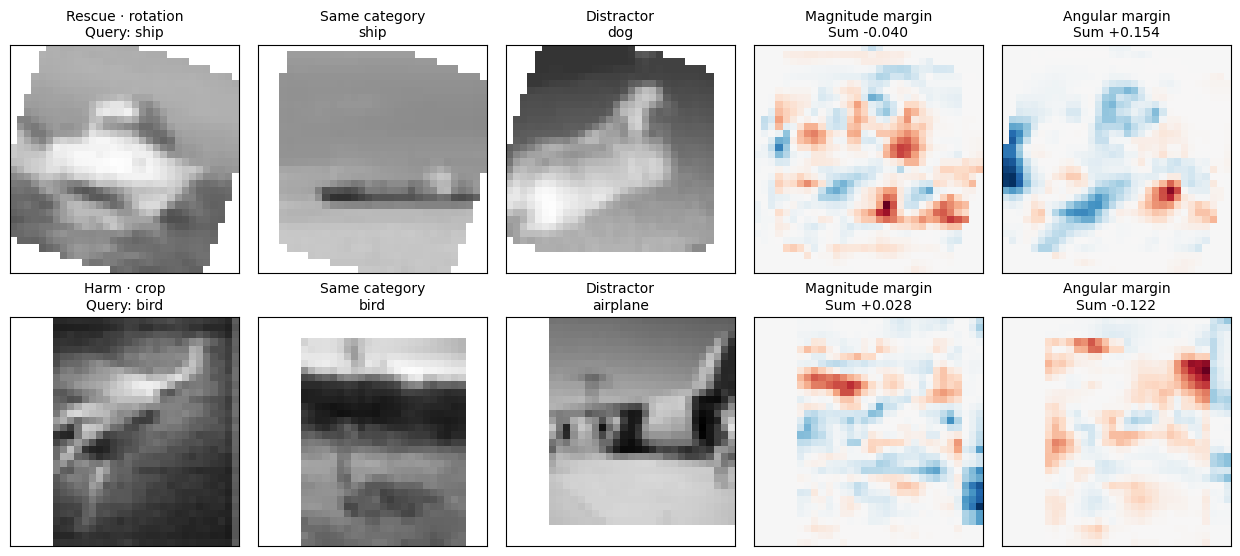

,switch,source,condition,row,column,mag_margin,angular_margin
8,rescue,7194,rotation,16,0,-0.001625,0.042246
9,rescue,7194,rotation,16,8,0.006978,0.033074
4,rescue,7194,rotation,8,0,0.000123,0.031462
17,harm,2464,crop,0,8,-0.000013,-0.020032
23,harm,2464,crop,8,24,-0.000486,-0.017266
19,harm,2464,crop,0,24,0.002118,-0.015383


In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12.4, 5.45), layout='constrained')
patch_rows = []
for row, example in zip(axes, examples):
    source, condition = example.source, example.condition
    k = CONDITIONS.index(condition)
    query = cifar_views(images[source]/255., condition, [PREVIOUS_SEED, int(source), k])[0]
    q = local_fields(query)[0]
    positive, pos_maps = reconstruct(query, q, example, example.positive)
    negative, neg_maps = reconstruct(query, q, example, example.negative)
    margins = neg_maps-pos_maps
    np.testing.assert_allclose(margins.sum((1,2)), [example.mag_margin, example.angular_margin], atol=1e-13)
    labels_ = [f'{example.switch.title()} · {condition}\nQuery: {CLASSES[labels[source]]}',
               f'Same category\n{CLASSES[labels[example.positive]]}',
               f'Distractor\n{CLASSES[labels[example.negative]]}']
    for ax, image, title in zip(row[:3], [np.where(query.valid, query.image, np.nan), positive, negative], labels_):
        ax.imshow(image, cmap='gray', vmin=0, vmax=1)
        ax.set_title(title, fontsize=10)
    for ax, values, name in zip(row[3:], margins, ['Magnitude margin', 'Angular margin']):
        bound = abs(values).max()
        ax.imshow(values, cmap='RdBu', vmin=-bound, vmax=bound)
        ax.set_title(f'{name}\nSum {values.sum():+.3f}', fontsize=10)
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
    for y in range(0,32,8):
        for x in range(0,32,8):
            m, a = margins[:,y:y+8,x:x+8].sum((1,2))
            patch_rows.append((example.switch, source, condition, y, x, m, a))
fig.savefig(R/'36_angular_scorecards.png', dpi=165)
plt.show()
patches = pd.DataFrame(patch_rows, columns=['switch','source','condition','row','column',
                                           'mag_margin','angular_margin'])
patches.to_csv(R/'audit_example_patch_margins.csv', index=False)
display(patches.sort_values('angular_margin', key=abs, ascending=False).groupby('switch').head(3))
